In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import jax.numpy as jnp
import numpy as np
from scipy.stats import qmc
import matplotlib.pyplot as plt
from corner import corner, overplot_lines, overplot_points

from utils.linear_model import get_ODR, get_OLS, xy2logxy

In [ ]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = np.random.uniform(0.1, 10, size=N)

y = 10 ** (k * np.log10(x) + b + np.random.normal(0, sig, size=N))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)

y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

In [ ]:
logx_obs, logy_obs, logx_err, logy_err = xy2logxy(x_obs, y_obs, x_err, y_err)

/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:39: RuntimeWarning: invalid value encountered in log10
  logx = np.log10(x)
/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:40: RuntimeWarning: invalid value encountered in log10
  logy = np.log10(y)
2026-11-24 19:57:18.901711: W external/xla/xla/service/gpu/nvptx_compiler.cc:765] The NVIDIA driver's CUDA version is 12.4 which is older than the ptxas CUDA version (12.6.77). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


In [ ]:
res_ODR = get_ODR(logx_obs, logy_obs)
res_OLS = get_OLS(logx_obs, logy_obs)

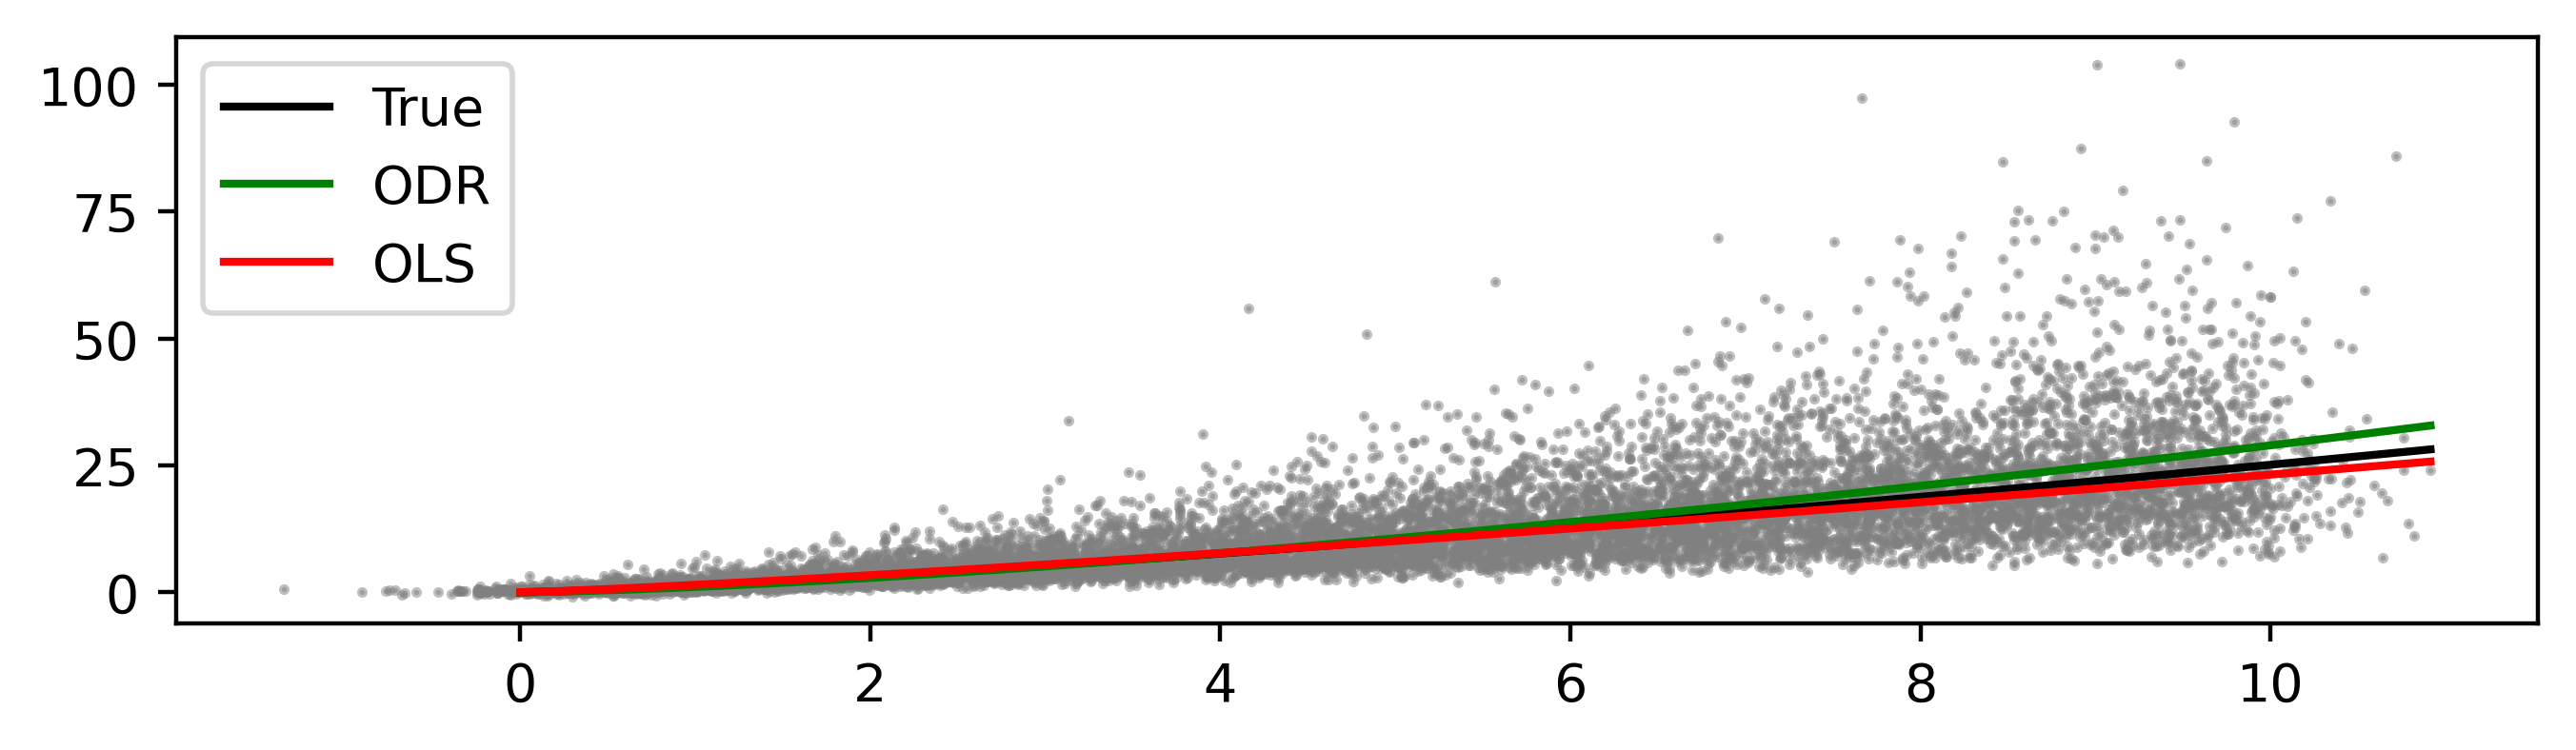

In [ ]:
plt.figure(figsize=(8, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10 ** (k * np.log10(xx) + b)
yy_ODR = 10 ** res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10 ** res_OLS['func'](np.log10(xx))

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from raddest.api.flowvi import FlowVI
from raddest.api.fitter import LogLinearML, LogLinearKS
from raddest.transfer import NegLogPlus

In [ ]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=NegLogPlus())

xflow.fit(x_obs, x_err, verbose=True)

  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:06<10:00,  6.06s/it]

  7%|▋         | 7/100 [00:06<01:00,  1.54it/s]

 14%|█▍        | 14/100 [00:06<00:23,  3.71it/s]

 21%|██        | 21/100 [00:06<00:12,  6.56it/s]

 28%|██▊       | 28/100 [00:06<00:07, 10.19it/s]

... (11 outputs left out)

step 0: loss 1.4651808738708496


step 10: loss 1.4444115161895752
step 20: loss 1.4342695474624634


step 30: loss 1.4310309886932373
step 40: loss 1.4291595220565796


step 50: loss 1.4273557662963867
step 60: loss 1.4266422986984253


In [ ]:
xflow.ks_test(x_obs, x_err, N=10000)

(0.019000016152858734, 0.19047779809919324)

In [ ]:
yflow = FlowVI(x_min=0,
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2,
               transfer=NegLogPlus())

yflow.fit(y_obs, y_err, verbose=True)

  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:05<09:12,  5.58s/it]

  8%|▊         | 8/100 [00:05<00:47,  1.92it/s]

 15%|█▌        | 15/100 [00:05<00:20,  4.25it/s]

 22%|██▏       | 22/100 [00:05<00:10,  7.31it/s]

 29%|██▉       | 29/100 [00:06<00:06, 11.19it/s]

... (11 outputs left out)

step 0: loss 2.6469409465789795
step 10: loss 2.6282215118408203


step 20: loss 2.618647575378418
step 30: loss 2.614812135696411


step 40: loss 2.615556240081787
step 50: loss 2.619478940963745


step 60: loss 2.6160340309143066


In [ ]:
yflow.ks_test(y_obs, y_err, N=10000)

(0.013899988494813442, 0.5555184423831971)

### ML Based Method

In [ ]:
logLinear_ML = LogLinearML(xflow, yflow)

In [ ]:
logLinear_ML.log_likelihood(
    x_obs, x_err, y_obs, y_err,
    jnp.array([[1.3, 0.1, 0.2], [1.2, 0.2, 0.1],
               [1.2, 0.1, -0.1]]))  # scale = -0.1 is regarded as 0.1

Array([-20893.027, -27506.44 , -29544.695], dtype=float32)

In [ ]:
logLinear_ML.log_posterior(
    x_obs, x_err, y_obs, y_err,
    jnp.array([[1.3, 0.1, 0.2], [1.2, 0.2, 0.1], [1.2, 0.1, -0.1]]))

Array([-20893.027, -27506.441,       -inf], dtype=float32)

In [ ]:
params_ml, params_std, cov = logLinear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1., 0., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.016779 0.02176387 0.17757323 -3.2085087


1000 1.2520741 0.13335186 0.20661396 -2.0905983


2000 1.2855433 0.10952843 0.20632152 -2.088729


3000 1.296198 0.1019327 0.2063049 -2.0885394


4000 1.2996308 0.099484816 0.20630698 -2.0885198


5000 1.3007368 0.098694876 0.20630854 -2.088518
converged, so stop with 5000 iterations


In [ ]:
print('ML fitted:', *params_ml)
print('Truth:', k, b, sig)

ML fitted: 1.3007368 0.098694876 0.20630854
Truth: 1.3 0.1 0.2


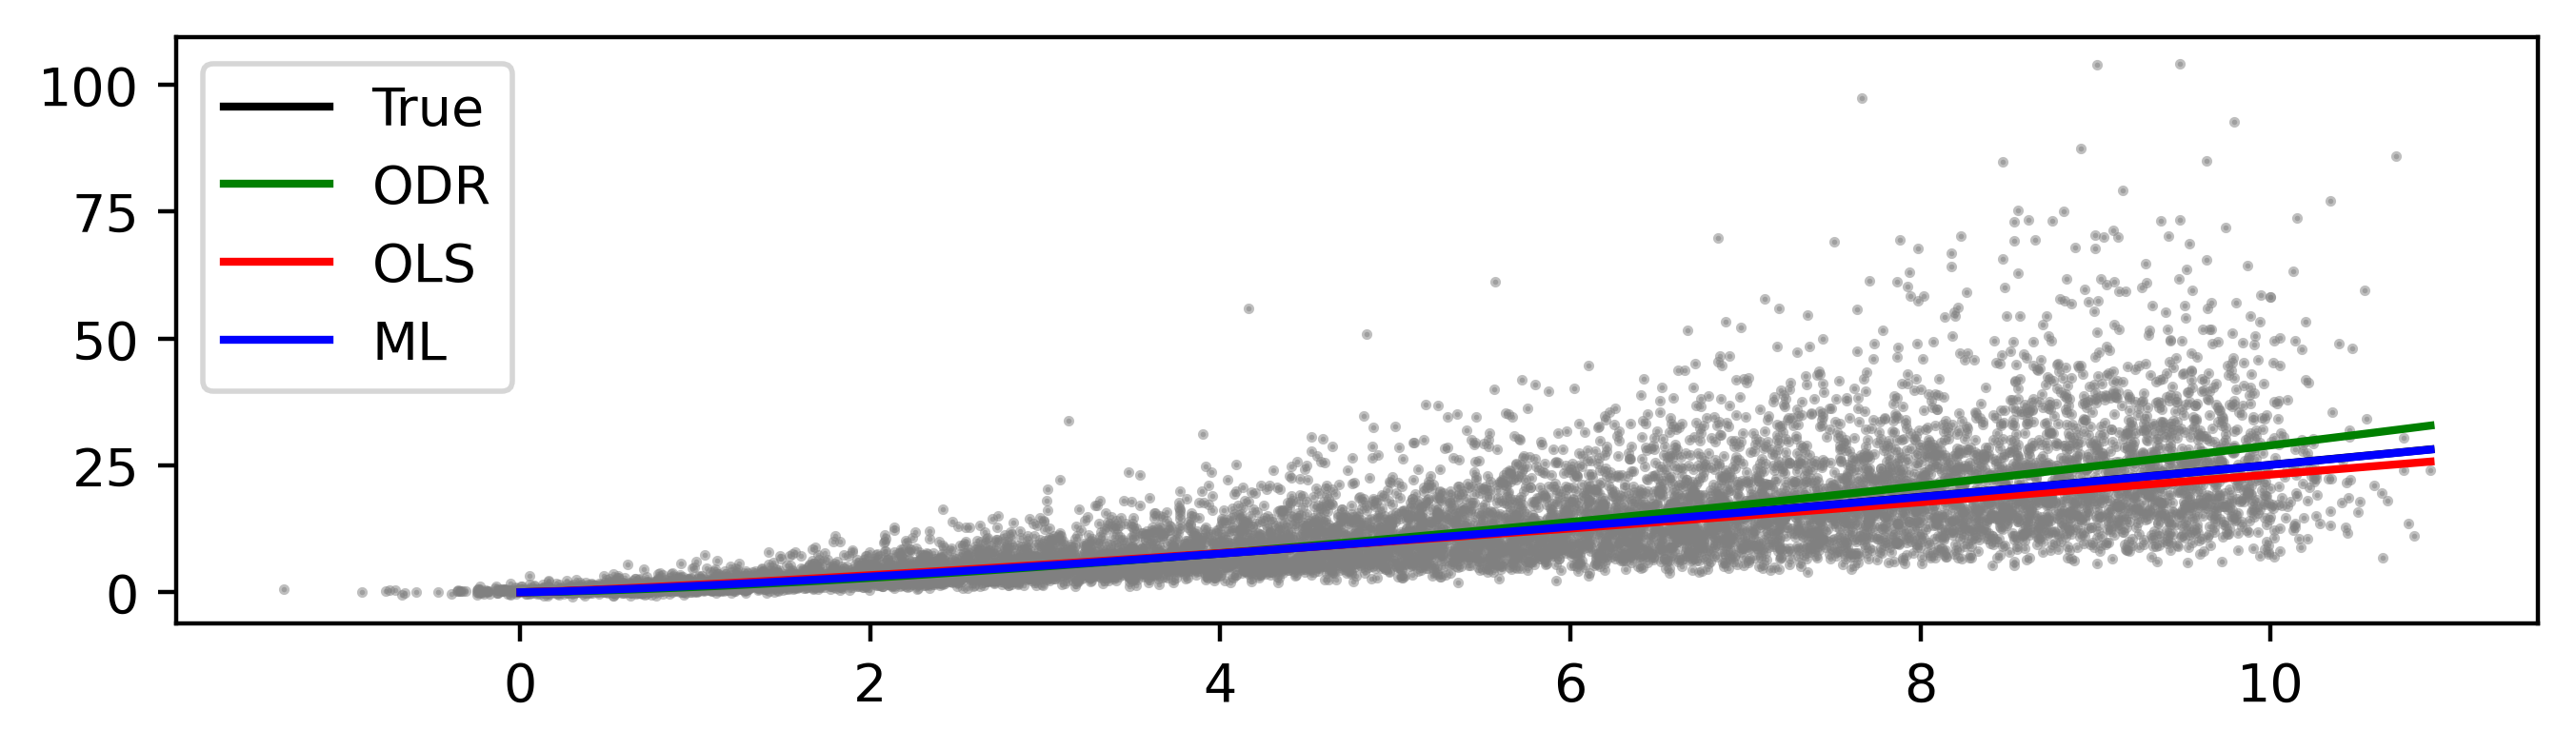

In [ ]:
plt.figure(figsize=(8, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10 ** (k * np.log10(xx) + b)
yy_ODR = 10 ** res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10 ** res_OLS['func'](np.log10(xx))
yy_ML = 10 ** (params_ml[0] * np.log10(xx) + params_ml[1])

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')
plt.plot(xx, yy_ML, color='blue', label='ML')

plt.legend()

In [ ]:
sampler = qmc.Sobol(d=3, scramble=True)
l_bounds = [
    max(params_ml[0] - 0.02, -2),
    max(params_ml[1] - 0.02, -2),
    max(params_ml[2] - 0.02, 0.1)
]
u_bounds = [
    min(params_ml[0] + 0.02, 2),
    min(params_ml[1] + 0.02, 2),
    min(params_ml[2] + 0.02, 0.5)
]
params_grid = qmc.scale(sampler.random_base2(m=15), l_bounds, u_bounds)

log_posterior = logLinear_ML.log_posterior(x_obs, x_err, y_obs, y_err,
                                               params_grid)

weight = jnp.exp(log_posterior - log_posterior.max())

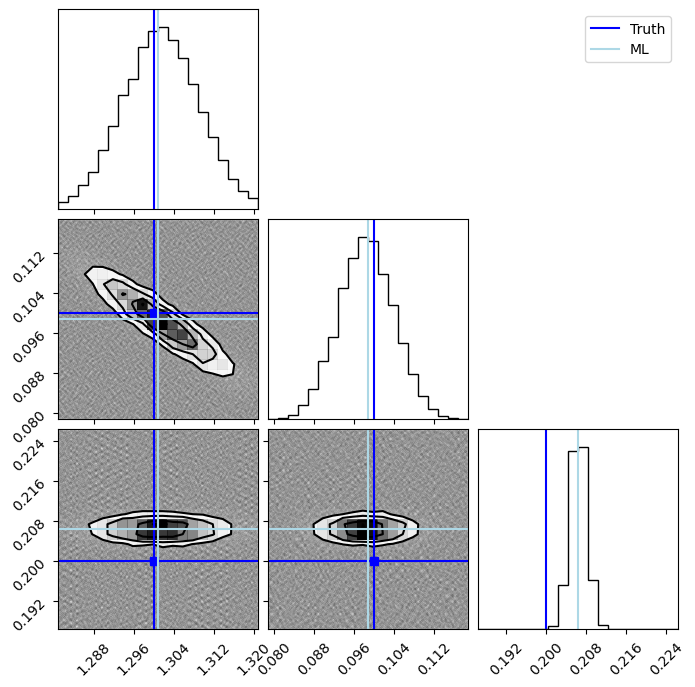

In [ ]:
cor_fig = corner(np.asarray(params_grid),
                 weights=weight,
                 bins=20,
                 truths=[k, b, sig],
                 truth_color='blue')
overplot_lines(cor_fig, params_ml, color='lightblue')
overplot_lines(cor_fig, [res_ODR['k'][0], res_ODR['b'][0], None],
               color='green')
overplot_lines(cor_fig, [res_OLS['k'][1], res_OLS['b'][1], None], color='red')

# get axes from fig
ax = cor_fig.axes[2]
ax.plot([], [], color='blue', label='Truth')
ax.plot([], [], color='lightblue', label='ML')
ax.legend(loc='upper right')

In [ ]:
sampler = qmc.Sobol(d=3, scramble=True)
l_bounds = [1.15, 0, max(params_ml[2] - 0.02, 0.1)]
u_bounds = [1.45, 0.2, min(params_ml[2] + 0.02, 0.5)]
params_grid = qmc.scale(sampler.random_base2(m=15), l_bounds, u_bounds)

log_posterior = logLinear_ML.log_posterior(x_obs, x_err, y_obs,
                                                     y_err, params_grid)

weight = jnp.exp(log_posterior - log_posterior.max())

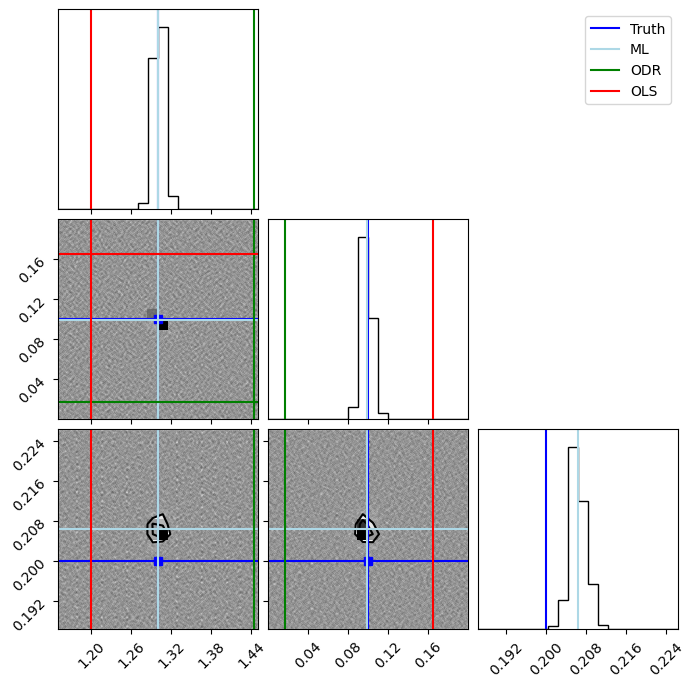

In [ ]:
cor_fig = corner(np.asarray(params_grid),
                 weights=weight,
                 bins=20,
                 truths=[k, b, sig],
                 truth_color='blue')
overplot_lines(cor_fig, params_ml, color='lightblue')
overplot_lines(cor_fig, [res_ODR['k'][0], res_ODR['b'][0], None],
               color='green')
overplot_lines(cor_fig, [res_OLS['k'][0], res_OLS['b'][0], None], color='red')

# get axes from fig
ax = cor_fig.axes[2]
ax.plot([], [], color='blue', label='Truth')
ax.plot([], [], color='lightblue', label='ML')
ax.plot([], [], color='green', label='ODR')
ax.plot([], [], color='red', label='OLS')
ax.legend(loc='upper right')

In [ ]:
x_obs_gen, y_obs_gen, x_err_gen, y_err_gen, x_gen, y_gen = logLinear_ML.sample(
    params_ml)

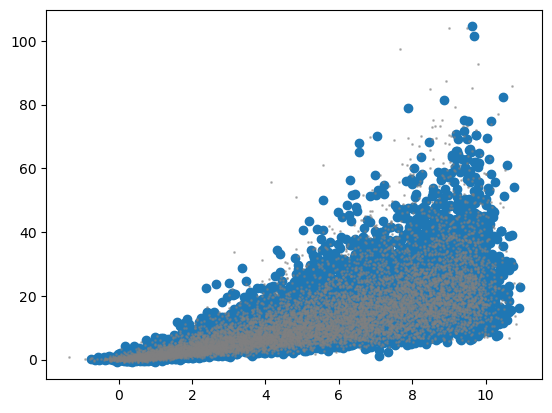

In [ ]:
plt.scatter(x_obs_gen, y_obs_gen)
plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)

In [ ]:
logLinear_ML.ks_test(params_ml, x_obs, y_obs)

(0.013750000856816769, 0.4874340479836535)

In [ ]:
D_lst, p_lst = logLinear_ML.ks_test(params_ml, x_obs, y_obs, K=10)

In [ ]:
10**np.mean(np.log10(p_lst))

0.2206908084597946

### KS Based Method

In [ ]:
logLinear_KS = LogLinearKS(xflow, yflow)

In [ ]:
params_mean, params_std, res_arr = logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

/home/jingtao/software/anaconda3/envs/raddest/lib/python3.9/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


----
k: 1.324 +/- 0.128
b: 0.094 +/- 0.093
sig: 0.209 +/- 0.037


----
k: 1.293 +/- 0.118
b: 0.106 +/- 0.085
sig: 0.208 +/- 0.037


----
k: 1.300 +/- 0.103
b: 0.099 +/- 0.082
sig: 0.204 +/- 0.040


----
k: 1.291 +/- 0.099
b: 0.105 +/- 0.076
sig: 0.210 +/- 0.042


----
k: 1.302 +/- 0.098
b: 0.097 +/- 0.074
sig: 0.215 +/- 0.043


... (3 outputs left out)

----
k: 1.285 +/- 0.095
b: 0.112 +/- 0.076
sig: 0.220 +/- 0.041


----
k: 1.297 +/- 0.094
b: 0.103 +/- 0.075
sig: 0.212 +/- 0.041


----
k: 1.298 +/- 0.091
b: 0.100 +/- 0.071
sig: 0.208 +/- 0.036
max iteration reached


[1.2902374  0.10647477 0.21039549] [0.09303066 0.07123111 0.038969  ]


In [ ]:
regressor_logLinear_KS_quantile = LogLinearKS(xflow, yflow, gen_new_grid='quantile')

In [ ]:
params_mean, params_std, res_arr = regressor_logLinear_KS_quantile.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

----
k: 1.335 +/- 0.098
b: 0.084 +/- 0.072
sig: 0.209 +/- 0.030


----
k: 1.295 +/- 0.099
b: 0.099 +/- 0.075
sig: 0.201 +/- 0.039


----
k: 1.296 +/- 0.085
b: 0.103 +/- 0.067
sig: 0.204 +/- 0.037


----
k: 1.296 +/- 0.097
b: 0.098 +/- 0.077
sig: 0.212 +/- 0.038


----
k: 1.318 +/- 0.095
b: 0.086 +/- 0.077
sig: 0.207 +/- 0.040


----
k: 1.304 +/- 0.091
b: 0.097 +/- 0.070
sig: 0.207 +/- 0.041


... (2 outputs left out)

----
k: 1.312 +/- 0.095
b: 0.089 +/- 0.075
sig: 0.204 +/- 0.038


----
k: 1.307 +/- 0.096
b: 0.089 +/- 0.076
sig: 0.208 +/- 0.037


----
k: 1.324 +/- 0.099
b: 0.083 +/- 0.078
sig: 0.205 +/- 0.038
max iteration reached


[1.31063939 0.08930499 0.2059253 ] [0.09451623 0.07397913 0.03888299]
